# QQQ Machine Learning Strategy Backtest

## Objective

Investigate whether predictions from the selected Random Forest
can inform a simple, executable QQQ trading strategy.

### Trading Rules

1. Generate a return prediction after the current trading day's close.
2. If the prediction is positive, enter a long QQQ position at
   the following trading day's open.
3. Exit the position at that day's close.
4. Otherwise, remain in cash.
5. Do not use leverage or short selling.

### Evaluation

- Compare against an always-invested intraday benchmark.
- Report conventional QQQ buy-and-hold separately.
- Evaluate cumulative returns and risk.
- Examine sensitivity to transaction costs.
- Do not optimize trading rules based on test-period results.

### Important Limitation

The model forecasts close-to-close returns, while the executable
strategy captures open-to-close returns.

This is an exploratory strategy analysis, not independent
confirmation of trading profitability.

In [4]:
from pathlib import Path

print("Current directory:", Path.cwd())

print("\nCSV in current directory:")
print((Path.cwd() / "data" / "qqq_model_data.csv").exists())

print("\nCSV one directory above:")
print((Path.cwd().parent / "data" / "qqq_model_data.csv").exists())

print("\nCSV in your Mac project folder:")
print((Path.home() / "Projects" / "qqq-returns-ml" / "data" / "qqq_model_data.csv").exists())

Current directory: /Users/michaelsipahimalani/Projects/qqq-returns-ml/notebooks

CSV in current directory:
False

CSV one directory above:
True

CSV in your Mac project folder:
True


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from pathlib import Path
from sklearn.ensemble import RandomForestRegressor

# Locate our project
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

# Load the existing modeling dataset
model_data = pd.read_csv(
    project_dir / "data" / "qqq_model_data.csv",
    index_col="Date",
    parse_dates=["Date"]
)

# Use the original features and target
feature_cols = [
    "Daily_Return_Pct",
    "Momentum_5d_Pct",
    "Volatility_20d_Pct",
    "MA_Distance_20d_Pct"
]

target_col = "Target_Next_Day_Return_Pct"

# Recreate the original split
n = len(model_data)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_data = model_data.iloc[:train_end - 1].copy()
test_data = model_data.iloc[val_end:].copy()

# Reconstruct the frozen model
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=3,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    train_data[feature_cols],
    train_data[target_col]
)

# Generate test-period trading signals
test_predictions = rf_model.predict(test_data[feature_cols])

print("Test observations:", len(test_data))
print("Model ready.")

Test observations: 626
Model ready.


In [6]:
# Download daily QQQ prices for the original historical period
price_data = yf.download(
    "QQQ",
    start="2010-01-01",
    end="2026-09-02",
    auto_adjust=True,
    multi_level_index=False,
    progress=False
)

if price_data.empty:
    raise ValueError("QQQ price download failed.")

# Ensure chronological ordering
price_data.index = pd.to_datetime(price_data.index)

if price_data.index.tz is not None:
    price_data.index = price_data.index.tz_localize(None)

price_data = price_data.sort_index()

# Verify available prices
print("First date:", price_data.index.min().date())
print("Last date:", price_data.index.max().date())

price_data[["Open", "Close"]].tail()

First date: 2010-01-04
Last date: 2026-09-01


,Open,Close
Date,,
2026-08-26,707.672576,710.629517
2026-08-27,716.183733,720.359375
2026-08-28,718.990817,715.684265
2026-08-31,714.425544,716.013916
2026-09-01,706.653642,706.903381


In [7]:
# Find the next trading session for each prediction date
next_trade_dates = (
    price_data.index.to_series()
    .shift(-1)
    .reindex(test_data.index)
)

# Get the next session's opening and closing prices
next_open = price_data["Open"].shift(-1).reindex(test_data.index)
next_close = price_data["Close"].shift(-1).reindex(test_data.index)

# Construct our trading dataset
backtest = pd.DataFrame({
    "Signal_Date": test_data.index,
    "Trade_Date": next_trade_dates.to_numpy(),
    "Predicted_Return_Pct": test_predictions,
    "Signal": (test_predictions > 0).astype(int),
    "Next_Open": next_open.to_numpy(),
    "Next_Close": next_close.to_numpy()
})

# Stop if any execution prices are missing
if backtest[["Trade_Date", "Next_Open", "Next_Close"]].isna().any().any():
    raise ValueError("Missing trading dates or execution prices.")

# Use actual trade dates as our index
backtest = backtest.set_index("Trade_Date").sort_index()
backtest.index.name = "Trade_Date"

# Verify every trade occurs after its signal
assert (backtest.index > backtest["Signal_Date"]).all()

# Calculate the next session's open-to-close return
backtest["Intraday_Return"] = (
    backtest["Next_Close"] / backtest["Next_Open"] - 1
)

print("Trading observations:", len(backtest))
print("Days invested:", backtest["Signal"].sum())
print("Fraction of days invested:", backtest["Signal"].mean())

backtest.head()

Trading observations: 626
Days invested: 594
Fraction of days invested: 0.9488817891373802


,Signal_Date,Predicted_Return_Pct,Signal,Next_Open,Next_Close,Intraday_Return
Trade_Date,,,,,,
2024-03-05,2024-03-04,0.072522,1,434.643027,429.822845,-0.011090
2024-03-06,2024-03-05,0.071767,1,434.031922,432.523773,-0.003475
2024-03-07,2024-03-06,0.071767,1,436.101865,439.088593,0.006849
2024-03-08,2024-03-07,0.072522,1,439.443469,432.750427,-0.015231
2024-03-11,2024-03-08,0.071767,1,431.262019,431.143738,-0.000274


In [8]:
# Store daily returns for each strategy
strategy_returns = {}

# Test three transaction-cost assumptions
for cost_bps in [0, 5, 10]:

    cost = cost_bps / 10000

    strategy_returns[f"Random Forest ({cost_bps} bps)"] = (
        backtest["Signal"] *
        (backtest["Intraday_Return"] - cost)
    )

# Benchmark 1: Buy at every open, sell at every close
strategy_returns["Always Intraday (5 bps)"] = (
    backtest["Intraday_Return"] - 5 / 10000
)

# Benchmark 2: Conventional buy-and-hold
buy_hold_returns = (
    price_data["Close"]
    .pct_change()
    .reindex(backtest.index)
    .copy()
)

# The benchmark begins at the first trading day's open
buy_hold_returns.iloc[0] = backtest["Intraday_Return"].iloc[0]

# Approximate a 5-bps total round-trip cost:
# 2.5 bps on entry and 2.5 bps on exit
buy_hold_returns.iloc[0] -= 2.5 / 10000
buy_hold_returns.iloc[-1] -= 2.5 / 10000

strategy_returns["Buy and Hold (5 bps)"] = buy_hold_returns

print("Strategy returns calculated.")

Strategy returns calculated.


In [9]:
def summarize_performance(daily_returns):

    # Growth of $1 invested
    equity = (1 + daily_returns).cumprod()

    # Annualize using approximately 252 trading days
    annualized_return = (
        equity.iloc[-1] ** (252 / len(daily_returns)) - 1
    )

    annualized_volatility = (
        daily_returns.std() * np.sqrt(252)
    )

    # Sharpe ratio using a zero risk-free rate assumption
    daily_std = daily_returns.std()

    if daily_std > 0:
        sharpe = (
            daily_returns.mean() / daily_std
        ) * np.sqrt(252)
    else:
        sharpe = np.nan

    # Measure decline from the previous equity peak
    running_peak = equity.cummax().clip(lower=1.0)

    drawdown = equity / running_peak - 1

    return {
        "Total Return (%)": (equity.iloc[-1] - 1) * 100,
        "Annualized Return (%)": annualized_return * 100,
        "Annualized Volatility (%)": annualized_volatility * 100,
        "Sharpe Ratio (rf=0)": sharpe,
        "Max Drawdown (%)": drawdown.min() * 100
    }


# Compare all strategies
strategy_performance = pd.DataFrame({
    name: summarize_performance(returns)
    for name, returns in strategy_returns.items()
}).T

strategy_performance.round(2)

,Total Return (%),Annualized Return (%),Annualized Volatility (%),Sharpe Ratio (rf=0),Max Drawdown (%)
Random Forest (0 bps),-9.55,-3.96,17.15,-0.15,-21.06
Random Forest (5 bps),-32.80,-14.79,17.15,-0.85,-34.62
Random Forest (10 bps),-50.08,-24.40,17.15,-1.54,-50.90
Always Intraday (5 bps),-28.89,-12.83,17.36,-0.70,-31.43
Buy and Hold (5 bps),62.56,21.60,21.28,1.03,-22.77


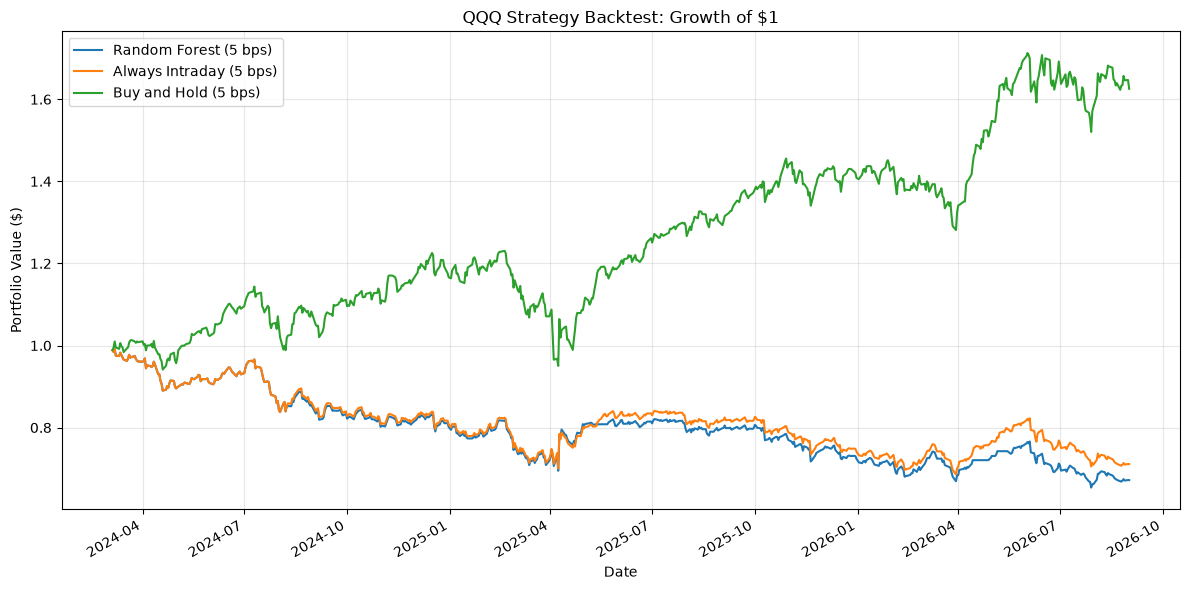

In [10]:
# Calculate cumulative portfolio growth
equity_curves = pd.DataFrame({
    name: (1 + returns).cumprod()
    for name, returns in strategy_returns.items()
})

# Display the main comparisons
equity_curves[
    [
        "Random Forest (5 bps)",
        "Always Intraday (5 bps)",
        "Buy and Hold (5 bps)"
    ]
].plot(figsize=(12, 6))

plt.title("QQQ Strategy Backtest: Growth of $1")
plt.xlabel("Date")
plt.ylabel("Portfolio Value ($)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
print("TRADING SIGNAL DIAGNOSTICS")

# Trading frequency
print("\nTotal trading sessions:", len(backtest))
print("Days invested:", int(backtest["Signal"].sum()))
print("Percentage of days invested:", round(backtest["Signal"].mean() * 100, 2))

# Relationship between predictions and tradable returns
intraday_correlation = backtest["Predicted_Return_Pct"].corr(
    backtest["Intraday_Return"]
)

print("\nPrediction-intraday correlation:", intraday_correlation)

# Compare returns on trading and non-trading days
long_days = backtest.loc[backtest["Signal"] == 1]
cash_days = backtest.loc[backtest["Signal"] == 0]

print("\nAverage intraday return when invested (%):",
      long_days["Intraday_Return"].mean() * 100)

print("Average intraday return when in cash (%):",
      cash_days["Intraday_Return"].mean() * 100)

TRADING SIGNAL DIAGNOSTICS

Total trading sessions: 626
Days invested: 594
Percentage of days invested: 94.89

Prediction-intraday correlation: 0.19649369676881892

Average intraday return when invested (%): -0.010813850756928743
Average intraday return when in cash (%): 0.22927536172794133
